<a href="https://colab.research.google.com/github/jedamurimuegues/Estadisitica-I---II/blob/main/Tarea_2_Estadistica_I_PYTHON.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TAREA 3: ESTADÍSTICA DESCRIPTIVA PARA VARIABLES CUALITATIVAS EN LENGUAJE PYTHON**

# **Análisis estadístico de los nacimientos en Colombia – 2024**

- Base de datos: BD-EEVV-Nacimientos-2024, proporcionada por el DANE.

- Variables de estudio: Tiempo de gestación (T_GES) y talla al nacer (TALLA_NAC).

- Análisis descriptivo y representación gráfica de las variables.

- Estudio de la asociación entre ambas variables.

**INTEGRANTES:**

1. Jeremy Muegues - Matemáticas.

**PROFESOR:**

- Andres Sebastian Rios Gutierrez.

**Curso:** Estadística I - **Grupo:** F1.

# **Introducción**

En este trabajo se realiza un análisis estadístico descriptivo de los nacimientos registrados en Colombia durante el año 2024, utilizando información proporcionada por el DANE. Se estudian las variables tiempo de gestación y talla al nacer, con el propósito de describir su comportamiento e identificar posibles asociaciones entre ellas mediante herramientas estadísticas y gráficas desarrolladas en Python.

In [ ]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from scipy.stats import shapiro
import plotly.express as px
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression
from scipy.stats import spearmanr, kendalltau

In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


In [8]:

io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1')
tabla.head(4)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1
50,573,1,1,NaN,2,7,5,2024,5,1,...,1,NaN,1,2,2.0,27,3,7,1.0,1


In [60]:
# Dimensiones de la base: (número de registros, número de columnas)
print("Dimensiones de la base:", tabla.shape)


Dimensiones de la base: (453901, 39)


In [ ]:
# Se conservan únicamente las dos variables de estudio: T_GES y TALLA_NAC
tabla1 = tabla[["T_GES", "TALLA_NAC"]]
tabla1.head(4)


,T_GES,TALLA_NAC
COD_DPTO,,
76,4,5
19,4,4
41,4,5
50,4,5


In [9]:
# Se revisan los valores únicos para identificar qué códigos existen
tabla1.T_GES.unique()

array([4, 3, 2, 6, 9, 5, 1])

In [10]:
tabla1.TALLA_NAC.unique()

array([5, 4, 3, 2, 9, 6, 1])

In [35]:
# y detectar el código 9 ("ignorado")
df2 = tabla1[(tabla1.T_GES != 9) &
             (tabla1.TALLA_NAC != 9)]

df2.head(4)

,T_GES,TALLA_NAC
COD_DPTO,,
76,4,5
19,4,4
41,4,5
50,4,5


**Limpieza de datos**

Según el diccionario de datos del DANE, el código 9 en estas variables corresponde a «ignorado / sin información». No es una categoría real, sino un dato no registrado, por lo que se eliminan esos registros para no distorsionar las proporciones. Después del filtro se verifica cuántos registros se conservan.

In [38]:
df2.T_GES.value_counts().sort_index()

,count
T_GES,
1,19
2,1705
3,121314
4,319579
5,364
6,641


Con la base ya depurada (443.622 nacimientos), se procede a responder las preguntas del análisis: el comportamiento de cada variable por separado y la asociación entre ambas.

# **PREGUNTA 1.**

*¿Cómo se comporta la variable tiempo de gestación de un nacido vivo en Colombia (T_GES)?*

La variable T_GES clasifica el tiempo de gestación en categorías ordenadas:

| Categoría | Rango de semanas |
|---|---|
| 1 |Menos de 22 semanas|
| 2 | De 22 a 27 semanas|
| 3 | De 28 a 37 semanas |
| 4 | De 38 a 41 semanas |
| 5 | De 42 y más semanas|
| 6 | Ignorado |

Para describir esta variable se calculan las proporciones de cada categoría y se representan con un diagrama de barras (frecuencias absolutas) y un diagrama circular (proporciones).

In [42]:
prop_tges = df2.T_GES.value_counts(normalize=True).sort_index()*100

print(round(prop_tges, 2))

T_GES
1     0.00
2     0.38
3    27.35
4    72.04
5     0.08
6     0.14
Name: proportion, dtype: float64


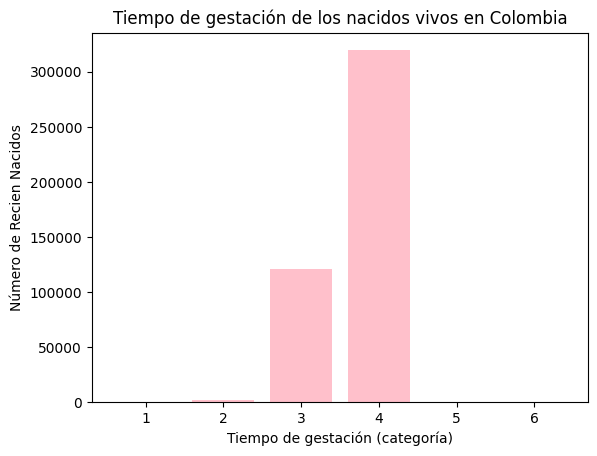

In [40]:
frecuencias = df2.T_GES.value_counts().sort_index()

x_values = frecuencias.index
y_values = frecuencias.values

plt.bar(x_values, y_values, color="pink")
plt.title("Tiempo de gestación de los nacidos vivos en Colombia")

ax = plt.subplot()
ax.set_xlabel("Tiempo de gestación (categoría)")
ax.set_ylabel("Número de Recien Nacidos")

plt.show()

En el gráfico se observa que la distribución del tiempo de gestación presenta una concentración considerable en las categorías 3 y 4. La categoría 4 que corresponde a el valor de 38-41 semanas donde hay mas de 300.000 niños recién nacidos y se registra la mayor proporción, con un 72.04 % de los nacimientos, seguida de la categoría 3 que corresponde a el valor de 28-37 semanas donde hay mas de 100.000 niños recién nacidos, con un 27.35 %. En conjunto, ambas categorías representan aproximadamente el 99.39 % de los registros. Por otra parte, las categorías 1, 2, 5 y 6 reúnen el 0.61 % restante, destacándose su baja participación, especialmente en las categorías 1 y 5, cuyas proporciones son prácticamente nulas.

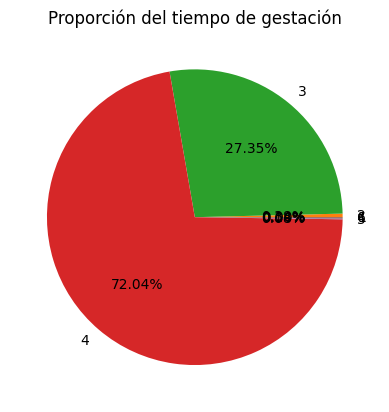

In [41]:
prop_tges = df2.T_GES.value_counts(normalize=True).sort_index()*100
plt.pie(prop_tges, labels=prop_tges.index, autopct="%1.2f%%")
plt.title("Proporción del tiempo de gestación")
plt.show()

En el diagrama circular se comprueba que la mayor proporción de nacimientos corresponde a la categoría 4 (72.04 %), seguida de la categoría 3 (27.35 %). Las demás categorías representan en conjunto apenas el 0.61 % de los registros, por lo que su participación es mínima.

# **PREGUNTA 2.**

*¿Cómo se comporta la variable talla de nacimiento de un nacido vivo en Colombia
(TALLA_NAC)?*

Se sigue el mismo procedimiento que con el tiempo de gestación: proporciones, diagrama de barras y diagrama circular. La variable TALLA_NAC también está codificada en categorías ordenadas de longitud al nacer (en centímetros, no en semanas):

| Categoría | Rango de talla (cm) |
|---|---|
| 1 | Menos de 20 cm|
| 2 | De 20 a 29 cm|
| 3 | De 30 a 39 cm|
| 4 | De 40 a 49 cm|
| 5 | De 50 a 59 cm|
| 6 | De 60 y más cm |

In [44]:
# Frecuencias absolutas y proporciones (%) de cada categoría de TALLA_NAC
frecuencias_talla = df2.TALLA_NAC.value_counts().sort_index()

proporciones_talla = df2.TALLA_NAC.value_counts(normalize=True).sort_index()*100

print("Cantidad de recién nacidos:")
print(frecuencias_talla)

print("\nPorcentaje de recién nacidos:")
print(round(proporciones_talla, 2))

Cantidad de recién nacidos:
TALLA_NAC
1         1
2       228
3      4506
4    212669
5    226209
6         9
Name: count, dtype: int64

Porcentaje de recién nacidos:
TALLA_NAC
1     0.00
2     0.05
3     1.02
4    47.94
5    50.99
6     0.00
Name: proportion, dtype: float64


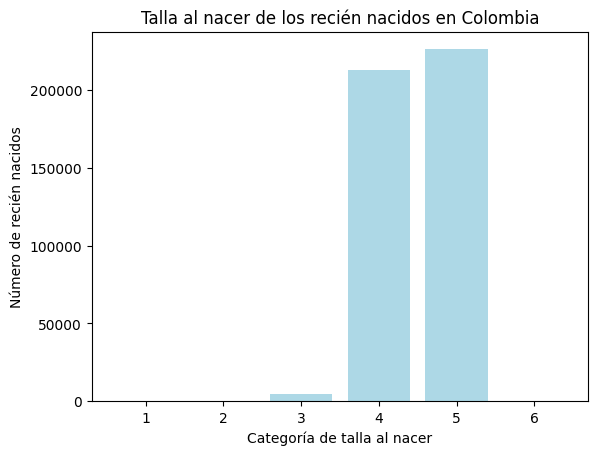

In [47]:
# Diagrama de barras: número de recién nacidos por categoría de talla
x_values = frecuencias_talla.index
y_values = frecuencias_talla.values

plt.bar(x_values, y_values, color="lightblue")
plt.title("Talla al nacer de los recién nacidos en Colombia")
ax = plt.subplot()
ax.set_xlabel("Categoría de talla al nacer")
ax.set_ylabel("Número de recién nacidos")

plt.show()

En el gráfico se observa que la distribución de la talla al nacer presenta una concentración considerable en las categorías 4 que corresponde a la talla de 40 a 49 cm y 5 que corresponde a la talla de 50 a 59 cm. La categoría 5 registra la mayor cantidad de nacimientos, con 226.209 recién nacidos y una proporción del 50.99 %, seguida de la categoría 4, con 212.669 recién nacidos y un 47.94 %. En conjunto, ambas categorías representan aproximadamente el 98.93 % de los registros. Por otra parte, las categorías 1, 2, 3 y 6 reúnen el 1.07 % restante, destacándose su baja participación, especialmente en las categorías 1 y 6, cuyas proporciones son prácticamente nulas.

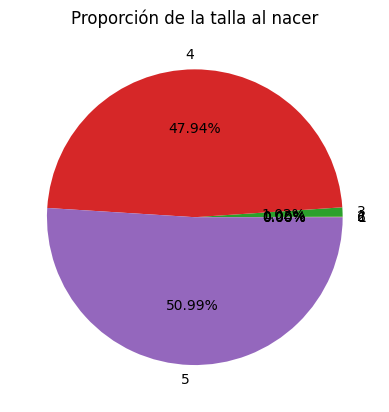

In [48]:
# Diagrama circular: proporción (%) de cada categoría de talla
plt.pie(frecuencias_talla, labels=frecuencias_talla.index, autopct="%1.2f%%")
plt.title("Proporción de la talla al nacer")
plt.show()

En el diagrama circular se comprueba que la mayor proporción de nacimientos corresponde a la categoría 5 (50.99 %), seguida de la categoría 4 (47.94 %). Las demás categorías representan en conjunto apenas el 1.07 % de los registros, por lo que su participación es mínima.

# **PREGUNTA 3.**

*¿Alguna variable depende de la otra, o, están asociadas? ¿Qué tan dependiente es una
variable de la otra o qué tan asociadas están ambas?*



Desde el punto de vista biológico es razonable plantear que, a mayor tiempo de gestación, el feto tiene más tiempo de desarrollo y nace con mayor talla. Para comprobar si los datos respaldan esta idea se estudia la asociación entre T_GES y TALLA_NAC.

El análisis de asociación se desarrolla en estos pasos:

1. Construir la tabla de contingencia (frecuencias conjuntas) y representarla con un mapa de calor.
2. Aplicar la prueba chi-cuadrado de independencia.
3. Calcular las probabilidades condicionales de la talla dado el tiempo de gestación.
4. Medir la fuerza de la asociación con el coeficiente de contingencia, phi y la V de Cramer.
5. Verificar el supuesto de frecuencias esperadas de la prueba.

In [49]:
# Tabla de contingencia: número de recién nacidos para cada combinación
# de categoría de T_GES (filas) y de TALLA_NAC (columnas)
tabla_contingencia = pd.crosstab(df2["T_GES"], df2["TALLA_NAC"])

print("Tabla de contingencia:")
print(tabla_contingencia)

Tabla de contingencia:
TALLA_NAC  1    2     3       4       5  6
T_GES                                     
1          1   17     1       0       0  0
2          0  186  1457      62       0  0
3          0   24  3015   86812   31463  0
4          0    0    22  125284  194264  9
5          0    0     0      92     272  0
6          0    1    11     419     210  0


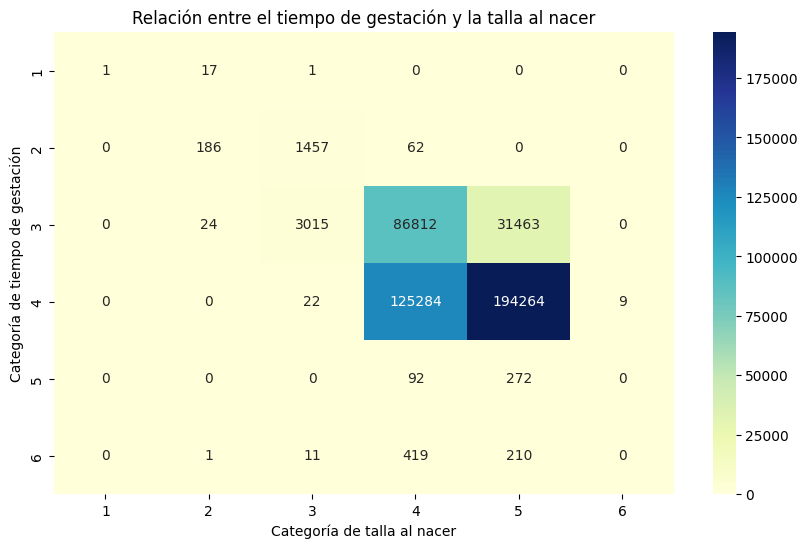

In [50]:
plt.figure(figsize=(10, 6))

sns.heatmap(tabla_contingencia, annot=True, fmt="d", cmap="YlGnBu")

plt.title("Relación entre el tiempo de gestación y la talla al nacer")
plt.xlabel("Categoría de talla al nacer")
plt.ylabel("Categoría de tiempo de gestación")

plt.show()

En el mapa de calor se observa la distribución conjunta del tiempo de gestación y la talla al nacer. Se evidencia una mayor concentración de nacimientos en la combinación de las categorías 4 de tiempo de gestación y 5 de talla al nacer, con 194.264 registros. Le sigue la combinación de las categorías 4 y 4, con 125.284 registros, y posteriormente las categorías 3 y 4, con 86.812 registros.

En general, las mayores frecuencias se concentran en las categorías 3 y 4 del tiempo de gestación, y en las categorías 4 y 5 de talla al nacer. Por otra parte, las demás combinaciones presentan frecuencias considerablemente menores.

In [51]:
from scipy import stats

res = stats.chi2_contingency(tabla_contingencia)
chi, valor_p, _, _ = res

print(
    f"El valor de la estadística Chi cuadrado es {chi} "
    f"y el valor p es {valor_p}"
)

El valor de la estadística Chi cuadrado es 259590.42692208404 y el valor p es 0.0


**Prueba chi-cuadrado de independencia**

- H₀: T_GES y TALLA_NAC son independientes.
- H₁: existe dependencia (asociación) entre T_GES y TALLA_NAC.
- Nivel de significancia: α = 0.05.

Regla de decisión:

* Si valor p < 0.05 se rechaza la hipótesis nula.
* Si valor p > 0.05 no se rechaza la hipótesis nula.

Al aplicar la prueba se obtuvo un estadístico chi-cuadrado de 259590.4269 con un valor p inferior a 0.05, por lo que se rechaza H₀: hay evidencia estadística de asociación entre el tiempo de gestación y la talla al nacer.

Con una muestra tan grande, la prueba chi-cuadrado detecta casi cualquier diferencia, por pequeña que sea. Por eso no basta con rechazar H₀: hay que medir además **qué tan fuerte** es la asociación, lo que se hace más adelante con la V de Cramer.

In [53]:
# 3. Probabilidades condicionales
prob_cond = pd.crosstab(
    df2["T_GES"],
    df2["TALLA_NAC"],
    normalize="index"
) * 100

print("Probabilidades condicionales P(TALLA_NAC | T_GES) en %:")
display(round(prob_cond, 2))

Probabilidades condicionales P(TALLA_NAC | T_GES) en %:


TALLA_NAC,1,2,3,4,5,6
T_GES,,,,,,
1,5.26,89.47,5.26,0.00,0.00,0.0
2,0.00,10.91,85.45,3.64,0.00,0.0
3,0.00,0.02,2.49,71.56,25.94,0.0
4,0.00,0.00,0.01,39.20,60.79,0.0
5,0.00,0.00,0.00,25.27,74.73,0.0
6,0.00,0.16,1.72,65.37,32.76,0.0


En la tabla de probabilidades condicionales se observa cómo se distribuye la talla al nacer dentro de cada categoría del tiempo de gestación. Para la categoría 2 de tiempo de gestación, el 85.45 % de los nacimientos corresponde a la categoría 3 de talla, mientras que para la categoría 3 de gestación predomina la categoría 4 de talla, con un 71.56 %.

Por otra parte, en las categorías 4 y 5 de tiempo de gestación se observa una mayor proporción de nacimientos en la categoría 5 de talla, con un 60.79 % y 74.73 %, respectivamente. Finalmente, en la categoría 6 de gestación predomina la categoría 4 de talla, con un 65.37 %.

Estos resultados muestran que la distribución de la talla al nacer cambia según la categoría del tiempo de gestación, lo que sugiere una posible asociación entre ambas variables.

In [61]:
import math

n = len(df2)

coeficiente_contingencia = math.sqrt(chi / (chi + n))
coeficiente_phi = math.sqrt(chi / n)
coeficiente_v_cramer = math.sqrt(
    chi / (n * min(tabla_contingencia.shape[0] - 1,
                   tabla_contingencia.shape[1] - 1))
)

print("Coeficiente de contingencia:", coeficiente_contingencia)
print("Coeficiente phi:", coeficiente_phi)
print("V de Cramer:", coeficiente_v_cramer)

Coeficiente de contingencia: 0.6075766401227416
Coeficiente phi: 0.7649583659018521
V de Cramer: 0.3420997812227397


El coeficiente de contingencia fue de 0.6076 y la V de Cramer de 0.3421. Según la escala de interpretación, este valor de V corresponde a una asociación **discreta**: la distribución de la talla al nacer cambia según el tiempo de gestación, pero la relación no es fuerte. Esto es coherente con las probabilidades condicionales, donde la mayoría de los nacimientos se concentra en las categorías 4 y 5 de talla en casi todos los grupos de gestación.

In [55]:
# Frecuencias esperadas bajo independencia, usadas para verificar el supuesto de la prueba

chi, valor_p, grados_libertad, frecuencias_esperadas = res

print("Frecuencias esperadas:")
print(pd.DataFrame(
    frecuencias_esperadas,
    index=tabla_contingencia.index,
    columns=tabla_contingencia.columns
).round(2))

Frecuencias esperadas:
TALLA_NAC     1       2        3          4          5     6
T_GES                                                       
1          0.00    0.01     0.19       9.11       9.69  0.00
2          0.00    0.88    17.32     817.36     869.40  0.03
3          0.27   62.35  1232.22   58157.01   61859.69  2.46
4          0.72  164.25  3246.06  153203.73  162957.76  6.48
5          0.00    0.19     3.70     174.50     185.61  0.01
6          0.00    0.33     6.51     307.29     326.85  0.01


In [56]:
# Cuántas celdas tienen frecuencia esperada menor que 5 (regla práctica de la prueba)
print("Cantidad de frecuencias esperadas menores que 5:",
      (frecuencias_esperadas < 5).sum())

print("Cantidad total de celdas:",
      frecuencias_esperadas.size)

Cantidad de frecuencias esperadas menores que 5: 17
Cantidad total de celdas: 36


Al analizar las frecuencias esperadas de la tabla de contingencia, se encontró que 17 de las 36 celdas presentan valores inferiores a 5, lo que corresponde aproximadamente al 47.22 % del total. Esta proporción supera el límite recomendado para la aplicación de la prueba chi-cuadrado, por lo que sus resultados deben interpretarse con precaución.

Para complementar el análisis, se calcularon el coeficiente de contingencia y el coeficiente V de Cramer, obteniendo valores de 0.6076 y 0.3421, respectivamente. Tomando como referencia la escala de interpretación presentada en la guía, el valor de V de Cramer indica una asociación discreta entre el tiempo de gestación y la talla al nacer.

Este resultado matiza la conclusión de la prueba chi-cuadrado: el rechazo de la independencia debe tomarse con cautela y apoyarse sobre todo en las probabilidades condicionales y en la V de Cramer.

# **Conclusión**

El análisis de los nacimientos registrados en Colombia durante el año 2024 permitió identificar que el tiempo de gestación presenta una concentración considerable en las categorías 3 y 4, correspondientes a los intervalos de 28 a 37 semanas y de 38 a 41 semanas, respectivamente. De manera similar, la talla al nacer muestra una mayor concentración en las categorías 4 y 5, que reúnen la gran mayoría de los registros analizados.

En cuanto a la relación entre ambas variables, las probabilidades condicionales muestran que la distribución de la talla al nacer presenta variaciones según la categoría del tiempo de gestación. Asimismo, el coeficiente V de Cramer (0.3421) indica una asociación discreta entre las variables, de acuerdo con la escala de referencia utilizada. Sin embargo, la prueba chi-cuadrado debe interpretarse con precaución, debido a que el 47.22 % de las frecuencias esperadas son inferiores a 5, lo que limita la confiabilidad de su aproximación.

En conjunto, los resultados permiten describir el comportamiento de ambas variables y evidenciar patrones de asociación entre el tiempo de gestación y la talla al nacer en los registros de nacimientos de Colombia durante 2024.

El análisis se realizó con 443.622 nacimientos tras la limpieza. Una asociación estadística no implica causalidad: los resultados describen cómo se relacionan las variables, no que una determine a la otra.

# **TAREA 2: ESTADÍSTICA DESCRIPTIVA PARA VARIABLES CUANTITATIVAS EN LENGUAJE PYTHON**

# **Análisis estadístico descriptivo de los nacimientos en Colombia – 2024**

- Base de datos: BD-EEVV-Nacimientos-2024, proporcionada por el DANE.
- Variables de estudio: Edad del padre (EDAD_PADRE) y número de embarazos de la madre (N_EMB).
- Gráficos estadísticos y medidas descriptivas para datos univariados.
- Evaluación del supuesto de normalidad mediante la prueba de Shapiro-Wilk.
- Ajuste y comparación de distribuciones de probabilidad Gamma y Weibull.
- Diagrama de dispersión para el análisis conjunto de las variables.
- Coeficientes de correlación de Pearson, Kendall y Spearman.

**INTEGRANTES:**

1.Jeremy Muegues - Matemáticas.


**PROFESOR:**

- Andres Sebastian Rios Gutierrez.

**Curso:** Estadística I - **Grupo:** F1.

# **Introducción**

En el presente trabajo se realiza un análisis estadístico descriptivo de la base de datos BD-EEVV-Nacimientos-2024, suministrada por el Departamento Administrativo Nacional de Estadística (DANE), la cual contiene información relacionada con los nacimientos registrados en Colombia.

Para este análisis se seleccionaron dos variables: la edad del padre (EDAD_PADRE) y el número de embarazos de la madre (N_EMB), con el propósito de estudiar su comportamiento y características principales.

Inicialmente, se desarrolla un análisis univariado mediante gráficos estadísticos y medidas descriptivas. Asimismo, se evalúa el supuesto de normalidad de las variables mediante la prueba de Shapiro-Wilk y la comparación de sus distribuciones. Finalmente, se analiza la relación entre ambas variables utilizando un diagrama de dispersión y los coeficientes de correlación de Pearson, Spearman y Kendall.


In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


In [ ]:
import io
import pandas as pd
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1')
tabla.head(4)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1
50,573,1,1,NaN,2,7,5,2024,5,1,...,1,NaN,1,2,2.0,27,3,7,1.0,1


In [ ]:
df = tabla[["EDAD_PADRE", "EDAD_MADRE", "N_EMB"]]
df.head(4)

,EDAD_PADRE,EDAD_MADRE,N_EMB
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1


# **PREGUNTA 1.**

¿Cómo se comporta la variable aleatoria de la edad de un padre de un recién nacido en Colombia (EDAD_PADRE)?

# **Gráficos Estadísticos**

Para dar respuesta a los objetivos planteados, se realizará un análisis de la variable (EDAD_PADRE) mediante diferentes gráficos estadísticos y medidas descriptivas, acompañados de sus respectivas interpretaciones. Esto permitirá observar el comportamiento de los datos, identificar sus principales características y evaluar el ajuste de diferentes distribuciones de probabilidad.

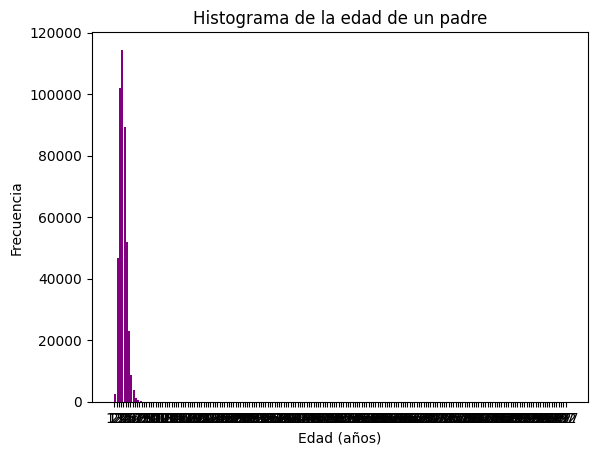

In [ ]:
import matplotlib.pyplot as plot
intervalos = range(min(df.EDAD_PADRE), max(df.EDAD_PADRE) +1, 5)

# Para construir el histograma
plot.hist(df.EDAD_PADRE, bins=intervalos, color='purple', rwidth=0.85)
plot.title("Histograma de la edad de un padre")
plot.xlabel("Edad (años)")
plot.ylabel("Frecuencia")
plot.xticks(intervalos)
plot.show()

In [ ]:

# Es necesario eliminar valores no representativoS (mayores a 100) debido a datos faltantes o errores de registro.

df1 = df[(df.EDAD_PADRE < 120) & (df.EDAD_MADRE !=99) & (df.N_EMB !=99)]
df.head(5)

,EDAD_PADRE,EDAD_MADRE,N_EMB
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1
50,31,4,5


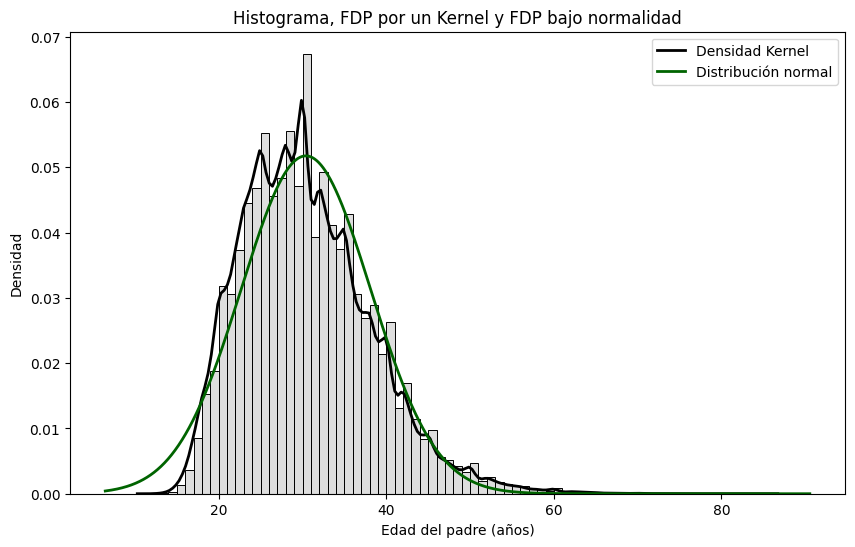

In [ ]:
# HISTOGRAMA
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE)+1)
plt.figure(figsize=(10, 6))

# Histograma (sin kde): barras grises con borde negro
sns.histplot(x=df1.EDAD_PADRE, bins=intervalos1, stat="density",
             color='lightgray', edgecolor="black")

# Densidad Kernel dibujada aparte, en morado
sns.kdeplot(x=df1.EDAD_PADRE, color='black', linewidth=2, label='Densidad Kernel')

# Curva normal con la media y la desviación estándar de los datos
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))
plt.plot(x, p, linewidth=2, label='Distribución normal', color="darkgreen")

plt.title('Histograma, FDP por un Kernel y FDP bajo normalidad')
plt.xlabel('Edad del padre (años)')
plt.ylabel('Densidad')
plt.legend()
plt.show()

Al comparar la distribución empírica de la variable (EDAD_PADRE), estimada mediante el método Kernel, con la función de densidad de probabilidad normal, se observa que ambas curvas no coinciden. La estimación Kernel presenta un pico más pronunciado alrededor de los 30 años, lo que indica una mayor concentración de datos entre los 25 y 35 años en comparación con lo que predice la distribución normal teórica.

In [ ]:
from scipy import stats
import numpy as np

# Ajuste de las distribuciones Gamma y Weibull
forma_g, loc_g, escala_g = stats.gamma.fit(df1.EDAD_PADRE, floc=0)
forma_w, loc_w, escala_w = stats.weibull_min.fit(df1.EDAD_PADRE, floc=0)

# Cálculo del AIC
aic_g = 4 - 2 * np.sum(stats.gamma.logpdf(df1.EDAD_PADRE, forma_g, loc_g, escala_g))
aic_w = 4 - 2 * np.sum(stats.weibull_min.logpdf(df1.EDAD_PADRE, forma_w, loc_w, escala_w))

# Resultados
print("DISTRIBUCIÓN GAMMA")
print("Parámetro de forma:", round(forma_g, 4))
print("Parámetro de escala:", round(escala_g, 4))
print("AIC:", round(aic_g, 4))

print("\nDISTRIBUCIÓN WEIBULL")
print("Parámetro de forma:", round(forma_w, 4))
print("Parámetro de escala:", round(escala_w, 4))
print("AIC:", round(aic_w, 4))

DISTRIBUCIÓN GAMMA
Parámetro de forma: 16.2054
Parámetro de escala: 1.8759
AIC: 3035269.9514

DISTRIBUCIÓN WEIBULL
Parámetro de forma: 4.0279
Parámetro de escala: 33.3885
AIC: 3100498.2877


Una vez estimados los parámetros de forma y escala de las distribuciones Gamma y Weibull, se procede a representar sus respectivas funciones de densidad sobre el histograma de la variable (EDAD_PADRE). Esto permite comparar visualmente el comportamiento de ambas distribuciones teóricas con la densidad empírica obtenida mediante el método Kernel y evaluar cuál presenta un mejor ajuste a los datos.

Debido a lo anterior, se implementan las distribuciones Gamma y Weibull como alternativas para evaluar un mejor ajuste a los datos.

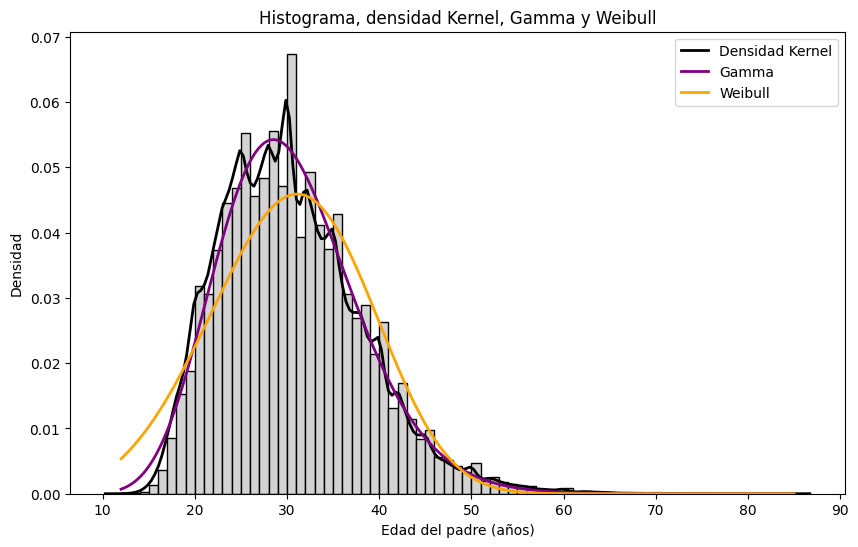

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df1.EDAD_PADRE, bins=intervalos1, density=True, color="lightgray", edgecolor="black")
sns.kdeplot(df1.EDAD_PADRE, color="black", linewidth=2, label="Densidad Kernel")

x = np.linspace(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE), 1000)
plt.plot(x, stats.gamma.pdf(x, forma_g, loc_g, escala_g), color="purple", linewidth=2, label="Gamma")
plt.plot(x, stats.weibull_min.pdf(x, forma_w, loc_w, escala_w), color="orange", linewidth=2, label="Weibull")

plt.title("Histograma, densidad Kernel, Gamma y Weibull")
plt.xlabel("Edad del padre (años)")
plt.ylabel("Densidad")
plt.legend()
plt.show()

In [ ]:
# Ajuste de distribuciones con loc = 0
forma_g, loc_g, escala_g = stats.gamma.fit(df1.EDAD_PADRE, floc=0)
forma_w, loc_w, escala_w = stats.weibull_min.fit(df1.EDAD_PADRE, floc=0)

# Log-verosimilitud
log_verosimilitud_g = np.sum(stats.gamma.logpdf(
    df1.EDAD_PADRE, forma_g, loc_g, escala_g
))

log_verosimilitud_w = np.sum(stats.weibull_min.logpdf(
    df1.EDAD_PADRE, forma_w, loc_w, escala_w
))

# AIC
k = 2  # forma y escala; loc está fijado en cero

AIC_gamma = 2*k - 2*log_verosimilitud_g
AIC_weibull = 2*k - 2*log_verosimilitud_w

print("AIC Gamma:", AIC_gamma)
print("AIC Weibull:", AIC_weibull)

AIC Gamma: 3035269.951373626
AIC Weibull: 3100498.2876989786




Al incorporar las distribuciones Gamma y Weibull, se observa que la curva Gamma presenta un mejor ajuste visual al comportamiento de la densidad empírica. Esta apreciación se confirma mediante el criterio de información de Akaike (AIC), cuyos resultados son 3.035.269,95 para Gamma y 3.100.498,29 para Weibull. Al presentar el menor valor, la distribución Gamma ofrece un mejor ajuste relativo entre las distribuciones comparadas.

Por lo tanto, no se asume normalidad para la variable analizada, ya que presenta una concentración marcada en las edades correspondientes a la adultez joven y una asimetría hacia las edades más avanzadas. Entre las distribuciones evaluadas, Gamma representa mejor el comportamiento observado de los datos.

# **Supuesto de normalidad - Shapiro**

La prueba de normalidad de Shapiro-Wilk se utiliza para contrastar si un conjunto de datos proviene de una población con distribución normal. Para ello, se plantea como hipótesis nula que los datos siguen una distribución normal, mientras que la hipótesis alternativa establece que no presentan dicha distribución.

In [ ]:
from scipy.stats import shapiro

# Con todos los datos (scipy avisará que el p-valor puede no ser exacto con n > 5000)
print(shapiro(df1.EDAD_PADRE))

# Con una muestra aleatoria de 5000 datos de la variable, sin reemplazo
idx = np.random.choice(len(df1.EDAD_PADRE), size=5000, replace=False)
print(shapiro(df1.EDAD_PADRE.iloc[idx]))

ShapiroResult(statistic=np.float64(0.9677117198585043), pvalue=np.float64(7.6156069148173195e-109))
ShapiroResult(statistic=np.float64(0.9651235066577304), pvalue=np.float64(3.8934201912997275e-33))


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443777.
  res = hypotest_fun_out(*samples, **kwds)


De acuerdo con los resultados obtenidos mediante la prueba de Shapiro-Wilk, se observa que los valores p son inferiores al nivel de significancia de 0.05. Por lo tanto, se rechaza la hipótesis nula de normalidad, lo que indica que los datos no presentan una distribución normal.  

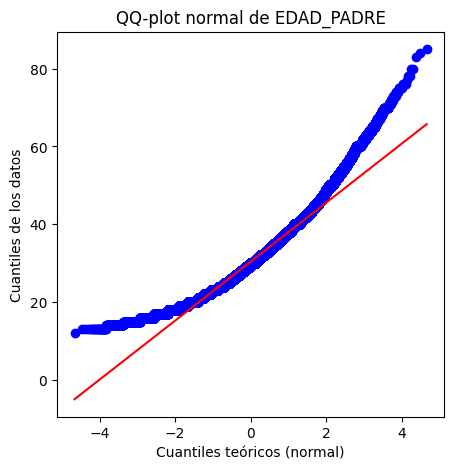

In [ ]:
from scipy import stats
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
stats.probplot(df1.EDAD_PADRE, dist="norm", plot=plt)
plt.title("QQ-plot normal de EDAD_PADRE")
plt.xlabel("Cuantiles teóricos (normal)")
plt.ylabel("Cuantiles de los datos")
plt.show()

De acuerdo con el gráfico Q-Q normal, se observa que los datos no siguen completamente la línea de referencia, presentando desviaciones principalmente en los extremos de la distribución. En la parte superior, los puntos se alejan considerablemente de la línea, lo que evidencia una mayor concentración de valores elevados respecto a los esperados bajo una distribución normal. Por lo tanto, se puede considerar que la variable (EDAD_PADRE) no presenta normalidad.

<Axes: ylabel='EDAD_PADRE'>

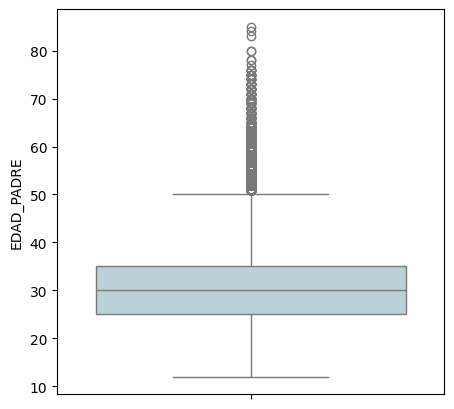

In [ ]:
# DIAGRAMA DE CAJAS Y BIGOTES
import seaborn as sns
plt.figure(figsize=(5, 5))
sns.boxplot(df1.EDAD_PADRE, color='lightblue', saturation=0.50)


De la gráfica estadística se puede observar que la variable edad del padre presenta una distribución con valores atípicos en las edades superiores a los 50 años. El primer cuartil se ubica aproximadamente en los 25 años, mientras que la mediana se encuentra alrededor de los 29 años y el tercer cuartil cerca de los 35 años. Esto indica que el 50 % central de los datos se concentra aproximadamente entre los 25 y 35 años.

El rango intercuartílico corresponde a la diferencia entre el tercer y el primer cuartil, y representa la amplitud del 50 % central de las observaciones. En este caso, se obtiene un rango intercuartílico aproximado de 10 años, lo que indica que la mitad central de las edades de los padres se encuentra distribuida en un intervalo relativamente reducido.

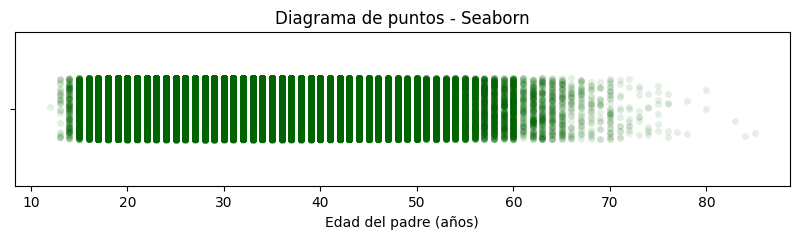

In [ ]:
plt.figure(figsize=(10, 2))
sns.stripplot(x=df1.EDAD_PADRE, color='darkgreen', alpha=0.1, jitter=0.2)
plt.title("Diagrama de puntos - Seaborn")
plt.xlabel("Edad del padre (años)")
plt.show()

De acuerdo con el diagrama de puntos, se observa una mayor concentración de datos en las edades intermedias, especialmente entre los 20 y 40 años. A medida que aumenta la edad del padre, la cantidad de observaciones tiende a disminuir, por lo que los puntos se vuelven más dispersos y escasos en las edades más avanzadas. Esto permite identificar una mayor frecuencia de registros en edades intermedias y una menor presencia en edades superiores.

# **Medidas Descriptivas**

In [ ]:
from scipy.stats import skew, kurtosis

print(f"Media: {np.mean(df1.EDAD_PADRE)}")
print(f"Mediana: {np.median(df1.EDAD_PADRE)} | Moda: {df1.EDAD_PADRE.mode()[0]}")
print(f"Varianza: {np.var(df1.EDAD_PADRE)} | Desviación estándar: {np.std(df1.EDAD_PADRE)}")
print(f"Asimetría: {skew(df1.EDAD_PADRE)}")
print(f"Curtosis: {kurtosis(df1.EDAD_PADRE)}")
print(f"Coeficiente de variación: {np.std(df1.EDAD_PADRE) / np.mean(df1.EDAD_PADRE)}")
print(df1.EDAD_PADRE.describe())   # mínimo, cuartiles y máximo

Media: 30.399666949841926
Mediana: 30.0 | Moda: 30
Varianza: 59.42512313787833 | Desviación estándar: 7.708769236258037
Asimetría: 0.7422600985923387
Curtosis: 0.8607555699997458
Coeficiente de variación: 0.2535807135314067
count    443777.000000
mean         30.399667
std           7.708778
min          12.000000
25%          25.000000
50%          30.000000
75%          35.000000
max          85.000000
Name: EDAD_PADRE, dtype: float64


**Media:** 30,40 años. La edad promedio de un padre de un recién nacido en Colombia es de aproximadamente 30 años.

**Mediana y moda:** 30 años ambas. El 50 % de los padres tiene 30 años o menos, y 30 es la edad que más se repite.

**Varianza y desviación estándar:** 59,43 y 7,71 años. Las edades se alejan en promedio unos 7,7 años de la media.

**Coeficiente de variación:** 0,25 (25 %). La desviación estándar equivale a cerca del 25 % de la media, una dispersión moderada.

**Primer y tercer cuartil (Q1/Q3):** 25 y 35 años. El 50 % central de los padres tiene entre 25 y 35 años.

**Mínimo y máximo:** 12 y 85 años. Las edades se mueven en un rango de 73 años.

**Asimetría:** 0,742. Es positiva, con extensión hacia las edades mayores.

**Curtosis:** 0,861. Al ser mayor que 0, la distribución es leptocúrtica: más concentrada alrededor de la media que una normal.

# **PREGUNTA 2.**

*¿Cómo se comporta la variable aleatoria del número de embarazos incluido el presente (N_EMB)?*

# **Diagrama de dispersión**

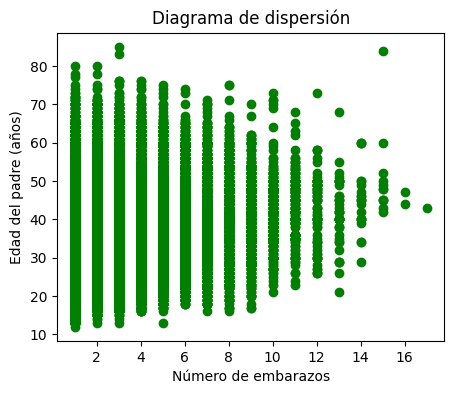

In [ ]:
# DIAGRAMA DE DISPERSION
plt.figure(figsize=(5, 4))
#  N_EMB toma pocos valores y los puntos se superponen
plt.scatter(df1["N_EMB"], df1["EDAD_PADRE"], color="green", marker="o")
plt.title("Diagrama de dispersión")
plt.xlabel("Número de embarazos")
plt.ylabel("Edad del padre (años)")
plt.show()

En el diagrama de dispersión se observa una alta concentración de datos en los primeros valores del número de embarazos. Aunque la nube de puntos presenta una amplia dispersión, se puede apreciar una tendencia positiva, lo que sugiere que la edad del padre y la cantidad de embarazos estarían relacionadas.

In [ ]:
# Se implementa un modelo de regresión lineal simple en Python
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()
modelo.fit(np.array(df1.N_EMB).reshape(-1, 1), np.array(df1.EDAD_PADRE).reshape(-1, 1))

# Se hacen las predicciones del modelo lineal
predi_lineal = modelo.predict(np.array(df1.N_EMB).reshape(-1, 1))

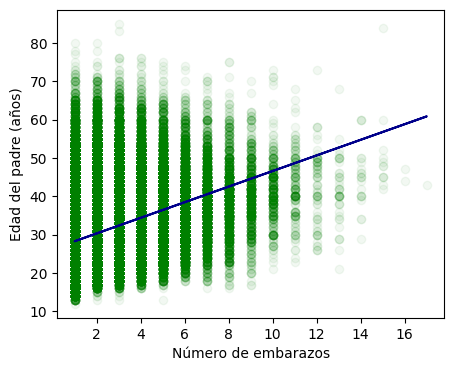

Pendiente: 2.0357572348073223 | Intercepto: 26.243428845677368


In [ ]:
plt.figure(figsize=(5, 4))
plt.scatter(df1["N_EMB"], df1["EDAD_PADRE"], color="green", marker="o", alpha=0.05)
plt.plot(df1.N_EMB, predi_lineal, linestyle="-", color="darkblue")
plt.xlabel("Número de embarazos")
plt.ylabel("Edad del padre (años)")
plt.show()

# valor de la pendiente, para interpretarla con un número
print("Pendiente:", modelo.coef_[0][0], "| Intercepto:", modelo.intercept_[0])

alpha=0.05: como N_EMB toma pocos valores (1, 2, 3...), miles de puntos caen en el mismo lugar. Con transparencia, las zonas más oscuras son donde hay más datos.
Pendiente: indica cuántos años más tiene el padre, en promedio, por cada embarazo adicional de la madre.
Dispersión grande: si la nube es amplia, el número de embarazos no determina por sí solo la edad del padre.



Diagrama de dispersión: la mayor concentración de datos está en los primeros valores de embarazos (de 1 a 9), y para cada valor las edades del padre se reparten en un rango amplio, de unos 15 a 70 años. A partir de 10 embarazos hay muy pocos registros.

Recta de regresión: la pendiente es positiva, así que a más embarazos de la madre tiende a ser mayor la edad del padre. Sin embargo, la gran dispersión alrededor de la recta indica que el número de embarazos no determina por sí solo la edad del padre.

Ademas, la recta se prolonga hasta 17 embarazos, pero pasando de 12 hay muy pocos datos, así que ahí la tendencia es poco confiable.

# **PREGUNTA 3.**

*¿Las variables están correlacionadas y qué grado de correlación tienen?*



# **Coeficientes de correlación de Pearson, de Kendall y de Spearman**

In [ ]:

# Grado de correlación o grado de dependencia

import numpy as np
from scipy.stats import spearmanr
from scipy.stats import kendalltau

coef_pearson = np.corrcoef(df1.N_EMB, df1.EDAD_PADRE)[0, 1]

coef_spearman, p_spearman = spearmanr(df1.N_EMB, df1.EDAD_PADRE)

coef_kendall, p_kendall = kendalltau(df1.N_EMB, df1.EDAD_PADRE)

print(f"El coeficiente de correlación de Pearson es: {coef_pearson}")
print(f"El coeficiente de correlación de Spearman es: {coef_spearman}")
print(f"El coeficiente de correlación de Kendall es: {coef_kendall}")

print(f"El valor p de Spearman es: {p_spearman}")
print(f"El valor p de Kendall es: {p_kendall}")


El coeficiente de correlación de Pearson es: 0.3400379040191506
El coeficiente de correlación de Spearman es: 0.36717068310509177
El coeficiente de correlación de Kendall es: 0.28723812222507816
El valor p de Spearman es: 0.0
El valor p de Kendall es: 0.0


Para la interpretación de los coeficientes de correlación nos ayudaremos de la referencia:

Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. biometrics, 159-174. [Link] (https://www.jstor.org/stable/pdf/2529310.pdf)

Los coeficientes de correlación trabajados se encuentran dentro del intervalo [-1, 1], donde los valores cercanos a -1 o 1 indican una asociación fuerte entre las variables, ya sea negativa o positiva, respectivamente. Por otro lado, los valores cercanos a 0 representan una asociación lineal o monotónica débil, dependiendo del coeficiente utilizado.

De lo anterior, se cumple que:


- **X y Y son independientes o no están correlacionadas** si:

  $$\rho(X,Y)\approx 0,\quad \eta(X,Y)\approx 0,\quad \kappa(X,Y)\approx 0.$$

- **Y depende insignificativamente de X o X y Y están insignificativamente correlacionadas** si:

  $$0<|\rho(X,Y)|<0.2,\quad 0<|\eta(X,Y)|<0.2,\quad 0<|\kappa(X,Y)|<0.2.$$

- **Y depende discretamente de X o X y Y están discretamente correlacionadas** si:

  $$0.2<|\rho(X,Y)|<0.4,\quad 0.2<|\eta(X,Y)|<0.4,\quad 0.2<|\kappa(X,Y)|<0.4.$$

- **Y depende moderadamente de X o X y Y están moderadamente correlacionadas** si:

  $$0.4<|\rho(X,Y)|<0.6,\quad 0.4<|\eta(X,Y)|<0.6,\quad 0.4<|\kappa(X,Y)|<0.6.$$

- **Y depende sustancialmente de X o X y Y están sustancialmente correlacionadas** si:

  $$0.6<|\rho(X,Y)|<0.8,\quad 0.6<|\eta(X,Y)|<0.8,\quad 0.6<|\kappa(X,Y)|<0.8.$$

- **Y depende fuertemente de X o X y Y están fuertemente correlacionadas** si:

  $$0.8<|\rho(X,Y)|<1,\quad 0.8<|\eta(X,Y)|<1,\quad 0.8<|\kappa(X,Y)|<1.$$


  

Teniendo en cuenta los resultados:

- Pearson (0.3400): correlación discretamente positiva.
- Spearman (0.3672): correlación discretamente positiva.
- Kendall (0.2872): correlación discretamente positiva.

Los tres coeficientes son positivos, lo que indica que existe una tendencia: a medida que aumenta el número de embarazos, también tiende a aumentar la edad del padre, esto debido a que se encuentran en el rango de [0.2, 0.4].

Al comparar los resultados obtenidos mediante los tres métodos, se observa que los coeficientes presentan valores relativamente cercanos, lo que refleja cierta consistencia en la asociación identificada. Aunque los métodos utilizan criterios diferentes para evaluar la correlación, todos coinciden en señalar una relación positiva entre las variables. No obstante, es importante señalar que la correlación no implica necesariamente una relación de causalidad entre ellas.

# **CONCLUSIONES**

A partir del análisis realizado sobre la base de datos BD-EEVV-Nacimientos-2024 del DANE, se encontró que la edad de los padres de los recién nacidos se concentra principalmente alrededor de los 30 años. Esto se evidencia en la media de 30,4 años y en que tanto la mediana como la moda corresponden a 30 años. Además, el 50 % central de los datos se encuentra entre los 25 y 35 años. La distribución presenta una asimetría positiva, lo que indica una mayor extensión hacia las edades superiores.

En cuanto al comportamiento de la distribución de la edad del padre, los gráficos y la prueba de Shapiro-Wilk permitieron establecer que los datos no siguen una distribución normal. Adicionalmente, al comparar los ajustes Gamma y Weibull, se encontró que la distribución Gamma presenta un mejor ajuste relativo, debido a que obtuvo un menor valor del criterio AIC.

Por otra parte, al estudiar la relación entre el número de embarazos de la madre y la edad del padre, se observó una tendencia positiva. Los coeficientes de Pearson (0,3400), Spearman (0,3672) y Kendall (0,2872) indican que existe una correlación positiva discreta entre ambas variables. Esto significa que, en los registros analizados, un mayor número de embarazos tiende a relacionarse con una mayor edad del padre. Sin embargo, la dispersión observada muestra que esta relación no es suficientemente fuerte para explicar por sí sola las diferencias en las edades de los padres.

Finalmente, los tres métodos de correlación presentaron resultados similares en cuanto al sentido y grado de asociación entre las variables. Esto permite identificar una relación estadística positiva, aunque no implica necesariamente que el aumento del número de embarazos sea la causa de una mayor edad del padre.